In [2]:
import os
import numpy as np
import cv2
import torch
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

class CrowdDataset(Dataset):
    def __init__(self, root, split, augment=False):
        self.img_dir = f"{root}/{split}/images"
        self.den_dir = f"{root}/{split}/density8"
        self.names = sorted(os.listdir(self.img_dir))
        self.augment = augment
        self.mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        self.std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

    def __len__(self):
        return len(self.names)

    def __getitem__(self, idx):
        name = self.names[idx]

        img = cv2.imread(f"{self.img_dir}/{name}")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        den = np.load(f"{self.den_dir}/{name.replace('.jpg', '.npy')}")

        # Random horizontal flip (image AND density map together)
        if self.augment and np.random.rand() < 0.5:
            img = img[:, ::-1]
            den = den[:, ::-1]

        # Scale to 0-1, then normalise with ImageNet mean/std
        img = (img.astype(np.float32) / 255.0 - self.mean) / self.std
        img = np.ascontiguousarray(img.transpose(2, 0, 1))   # (3, H, W)
        den = np.ascontiguousarray(den)[None, ...]            # (1, H/8, W/8)

        return torch.from_numpy(img), torch.from_numpy(den)

In [3]:
train_set = CrowdDataset("data/part_B", "train_data", augment=True)
test_set  = CrowdDataset("data/part_B", "test_data", augment=False)
print("Train size:", len(train_set), "| Test size:", len(test_set))

# One sample
img, den = train_set[0]
print("Image tensor:", img.shape)
print("Density tensor:", den.shape, "| sum =", round(den.sum().item(), 2))

# A batch of 4
train_loader = DataLoader(train_set, batch_size=4, shuffle=True, num_workers=0)
imgs, dens = next(iter(train_loader))
print("Batch images:", imgs.shape)
print("Batch density:", dens.shape)
print("Counts in batch:", dens.sum(dim=(1, 2, 3)))

# Check that every saved density map has the same size
folder = "data/part_B/train_data/density8"
shapes = {np.load(f"{folder}/{f}").shape for f in os.listdir(folder)}
print("Density map shapes found:", shapes)

Train size: 400 | Test size: 316
Image tensor: torch.Size([3, 768, 1024])
Density tensor: torch.Size([1, 96, 128]) | sum = 233.0
Batch images: torch.Size([4, 3, 768, 1024])
Batch density: torch.Size([4, 1, 96, 128])
Counts in batch: tensor([412.0000,  21.0000, 185.0000,  35.0000])
Density map shapes found: {(96, 128)}


In [4]:
import torch.nn as nn
from torchvision import models

class CSRNet(nn.Module):
    def __init__(self):
        super().__init__()
        # Front-end: first 10 conv layers of pretrained VGG-16 (ends after conv4_3 + ReLU)
        vgg = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
        self.frontend = nn.Sequential(*list(vgg.features.children())[:23])

        # Back-end: dilated convolutions
        self.backend = self._make_backend([512, 512, 512, 256, 128, 64])

        # Output: 64 channels -> 1 channel (the density map)
        self.output = nn.Conv2d(64, 1, kernel_size=1)

        # New layers start from small random weights
        for m in list(self.backend.modules()) + list(self.output.modules()):
            if isinstance(m, nn.Conv2d):
                nn.init.normal_(m.weight, std=0.01)
                nn.init.constant_(m.bias, 0)

    def _make_backend(self, cfg):
        layers = []
        in_ch = 512
        for v in cfg:
            layers += [nn.Conv2d(in_ch, v, kernel_size=3, padding=2, dilation=2),
                       nn.ReLU(inplace=True)]
            in_ch = v
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.frontend(x)
        x = self.backend(x)
        x = self.output(x)
        return x

device = torch.device("cuda")
model = CSRNet().to(device)

n_params = sum(p.numel() for p in model.parameters())
print("Total parameters:", f"{n_params:,}")

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to C:\Users\Vishesh/.cache\torch\hub\checkpoints\vgg16-397923af.pth
100.0%


Total parameters: 16,263,489


In [5]:
img, den = train_set[0]
x = img.unsqueeze(0).to(device)          # add a batch dimension -> (1, 3, 768, 1024)

model.eval()
with torch.no_grad():
    out = model(x)

print("Input shape :", x.shape)
print("Output shape:", out.shape)
print("Target shape:", den.unsqueeze(0).shape)
print("Predicted count (untrained):", out.sum().item())
print("True count:", den.sum().item())

# Memory test: can your 6 GB GPU handle a training step on a full-size image?
model.train()
torch.cuda.reset_peak_memory_stats()
out = model(x)
loss = ((out - den.unsqueeze(0).to(device)) ** 2).sum()
loss.backward()
print("Peak GPU memory used (MB):", round(torch.cuda.max_memory_allocated() / 1024**2))

Input shape : torch.Size([1, 3, 768, 1024])
Output shape: torch.Size([1, 1, 96, 128])
Target shape: torch.Size([1, 1, 96, 128])
Predicted count (untrained): -1.5681291818618774
True count: 233.0
Peak GPU memory used (MB): 1302


In [6]:
from torch.utils.data import Subset
import time

# 360 train / 40 validation, fixed seed so the split is the same every time
g = torch.Generator().manual_seed(42)
perm = torch.randperm(400, generator=g).tolist()
train_idx, val_idx = perm[:360], perm[360:]

train_ds = Subset(CrowdDataset("data/part_B", "train_data", augment=True),  train_idx)
val_ds   = Subset(CrowdDataset("data/part_B", "train_data", augment=False), val_idx)

train_loader = DataLoader(train_ds, batch_size=2, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=1, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_set, batch_size=1, shuffle=False, num_workers=0)

def evaluate(model, loader):
    model.eval()
    errs = []
    with torch.no_grad():
        for img, den in loader:
            pred = model(img.to(device)).sum().item()
            errs.append(pred - den.sum().item())
    errs = np.array(errs)
    return np.abs(errs).mean(), np.sqrt((errs ** 2).mean())

# Baseline: always predict the average training count
train_counts = np.array([train_ds[i][1].sum().item() for i in range(len(train_ds))])
val_counts   = np.array([val_ds[i][1].sum().item() for i in range(len(val_ds))])
guess = train_counts.mean()
print("Average training count:", round(guess, 1))
print("Baseline val MAE :", round(np.abs(val_counts - guess).mean(), 2))
print("Baseline val MSE :", round(np.sqrt(((val_counts - guess) ** 2).mean()), 2))

Average training count: 121.3
Baseline val MAE : 68.23
Baseline val MSE : 89.85


In [7]:
model = CSRNet().to(device)          # fresh model
optimizer = torch.optim.Adam(model.parameters(), lr=1e-5)
criterion = nn.MSELoss(reduction="sum")

EPOCHS = 3
best_mae = float("inf")

for epoch in range(1, EPOCHS + 1):
    model.train()
    t0 = time.time()
    total_loss = 0.0
    for img, den in train_loader:
        img, den = img.to(device), den.to(device)
        out = model(img)
        loss = criterion(out, den) / img.size(0)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    val_mae, val_rmse = evaluate(model, val_loader)
    if val_mae < best_mae:
        best_mae = val_mae
        torch.save(model.state_dict(), "best_model.pth")
        flag = "  <- saved"
    else:
        flag = ""
    print(f"Epoch {epoch}/{EPOCHS} | loss {total_loss/len(train_loader):.1f} | "
          f"val MAE {val_mae:.2f} | val MSE {val_rmse:.2f} | "
          f"{time.time()-t0:.0f}s{flag}")

Epoch 1/3 | loss 10.2 | val MAE 29.50 | val MSE 34.65 | 136s  <- saved
Epoch 2/3 | loss 5.2 | val MAE 17.84 | val MSE 28.79 | 137s  <- saved
Epoch 3/3 | loss 3.9 | val MAE 29.25 | val MSE 41.33 | 141s


In [8]:
import json

RESUME = False          # set to True only if you need to continue after a crash
EPOCHS = 60

model = CSRNet().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-5)
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[40], gamma=0.1)
criterion = nn.MSELoss(reduction="sum")

history = []
best_mae = float("inf")
start_epoch = 1

if RESUME and os.path.exists("last_checkpoint.pth"):
    ck = torch.load("last_checkpoint.pth")
    model.load_state_dict(ck["model"])
    optimizer.load_state_dict(ck["optimizer"])
    scheduler.load_state_dict(ck["scheduler"])
    history, best_mae = ck["history"], ck["best_mae"]
    start_epoch = ck["epoch"] + 1
    print("Resumed from epoch", ck["epoch"])

for epoch in range(start_epoch, EPOCHS + 1):
    model.train()
    t0 = time.time()
    total_loss = 0.0
    for img, den in train_loader:
        img, den = img.to(device), den.to(device)
        out = model(img)
        loss = criterion(out, den) / img.size(0)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    scheduler.step()

    val_mae, val_rmse = evaluate(model, val_loader)
    train_loss = total_loss / len(train_loader)
    history.append({"epoch": epoch, "loss": train_loss, "val_mae": float(val_mae), "val_mse": float(val_rmse)})

    flag = ""
    if val_mae < best_mae:
        best_mae = val_mae
        torch.save(model.state_dict(), "best_model.pth")
        flag = "  <- best"

    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(), "epoch": epoch,
                "history": history, "best_mae": best_mae}, "last_checkpoint.pth")
    with open("history.json", "w") as f:
        json.dump(history, f)

    print(f"Epoch {epoch}/{EPOCHS} | loss {train_loss:.1f} | val MAE {val_mae:.2f} | "
          f"val MSE {val_rmse:.2f} | {time.time()-t0:.0f}s{flag}")

print("Training finished. Best val MAE:", round(best_mae, 2))

Epoch 1/60 | loss 8.2 | val MAE 30.28 | val MSE 34.36 | 139s  <- best
Epoch 2/60 | loss 4.7 | val MAE 71.57 | val MSE 81.06 | 140s
Epoch 3/60 | loss 4.9 | val MAE 35.68 | val MSE 49.86 | 141s
Epoch 4/60 | loss 3.9 | val MAE 33.69 | val MSE 41.05 | 141s
Epoch 5/60 | loss 3.3 | val MAE 36.72 | val MSE 40.66 | 140s
Epoch 6/60 | loss 3.0 | val MAE 19.69 | val MSE 30.93 | 140s  <- best
Epoch 7/60 | loss 3.0 | val MAE 27.73 | val MSE 35.10 | 139s
Epoch 8/60 | loss 2.5 | val MAE 32.15 | val MSE 41.44 | 138s
Epoch 9/60 | loss 2.1 | val MAE 13.18 | val MSE 23.11 | 138s  <- best
Epoch 10/60 | loss 3.7 | val MAE 14.47 | val MSE 24.01 | 139s
Epoch 11/60 | loss 2.5 | val MAE 32.18 | val MSE 40.77 | 140s
Epoch 12/60 | loss 1.9 | val MAE 14.70 | val MSE 22.03 | 139s
Epoch 13/60 | loss 1.9 | val MAE 16.03 | val MSE 24.77 | 138s
Epoch 14/60 | loss 2.0 | val MAE 15.52 | val MSE 21.96 | 140s
Epoch 15/60 | loss 1.6 | val MAE 11.66 | val MSE 20.17 | 138s  <- best
Epoch 16/60 | loss 1.8 | val MAE 20.47 | va

C:\Users\Vishesh\AppData\Local\Temp\ipykernel_9668\2029840365.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("best_model.pth"))   # a h

TEST RESULTS on 316 unseen images
Model    MAE : 9.03
Model    MSE : 14.34
Baseline MAE : 71.53 (always guess 121.3)

Total true people     : 39120
Total predicted people: 38458

5 worst images:
  IMG_75.jpg: true 539 | predicted 453 | error -86
  IMG_80.jpg: true 470 | predicted 404 | error -66
  IMG_74.jpg: true 261 | predicted 201 | error -60
  IMG_40.jpg: true 331 | predicted 280 | error -51
  IMG_237.jpg: true 323 | predicted 278 | error -45


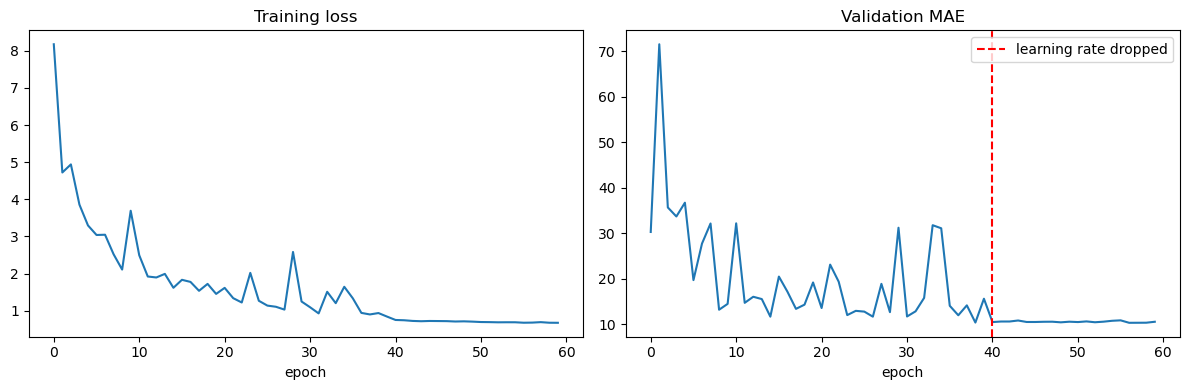

In [9]:
model = CSRNet().to(device)
model.load_state_dict(torch.load("best_model.pth"))   # a harmless FutureWarning may appear
model.eval()

rows = []
with torch.no_grad():
    for i, (img, den) in enumerate(test_loader):
        pred = model(img.to(device)).sum().item()
        true = den.sum().item()
        rows.append((test_set.names[i], true, pred, pred - true))

errs  = np.array([r[3] for r in rows])
trues = np.array([r[1] for r in rows])

print("TEST RESULTS on", len(rows), "unseen images")
print("Model    MAE :", round(np.abs(errs).mean(), 2))
print("Model    MSE :", round(np.sqrt((errs ** 2).mean()), 2))
print("Baseline MAE :", round(np.abs(trues - 121.3).mean(), 2), "(always guess 121.3)")
print()
print("Total true people     :", int(trues.sum()))
print("Total predicted people:", round(sum(r[2] for r in rows)))
print()
print("5 worst images:")
for name, t, p, e in sorted(rows, key=lambda r: -abs(r[3]))[:5]:
    print(f"  {name}: true {t:.0f} | predicted {p:.0f} | error {e:+.0f}")

# Training curves
hist = json.load(open("history.json"))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot([h["loss"] for h in hist]);    ax[0].set_title("Training loss");        ax[0].set_xlabel("epoch")
ax[1].plot([h["val_mae"] for h in hist]); ax[1].set_title("Validation MAE");       ax[1].set_xlabel("epoch")
ax[1].axvline(40, color="red", linestyle="--", label="learning rate dropped")
ax[1].legend()
plt.tight_layout(); plt.show()

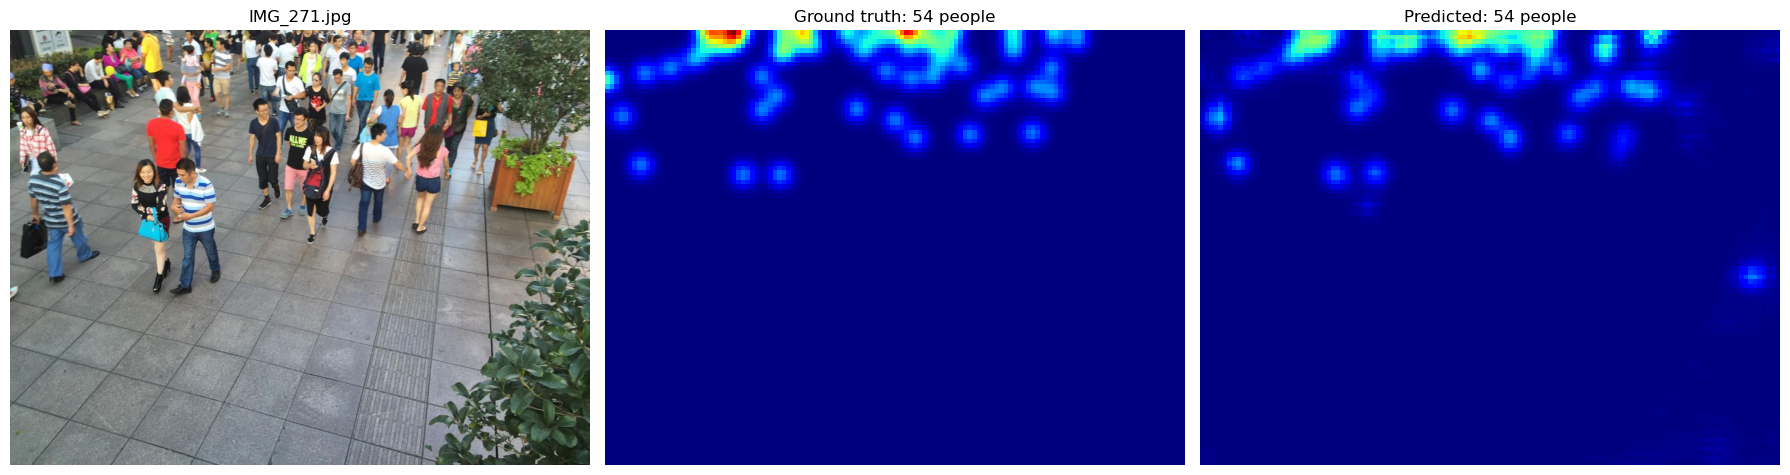

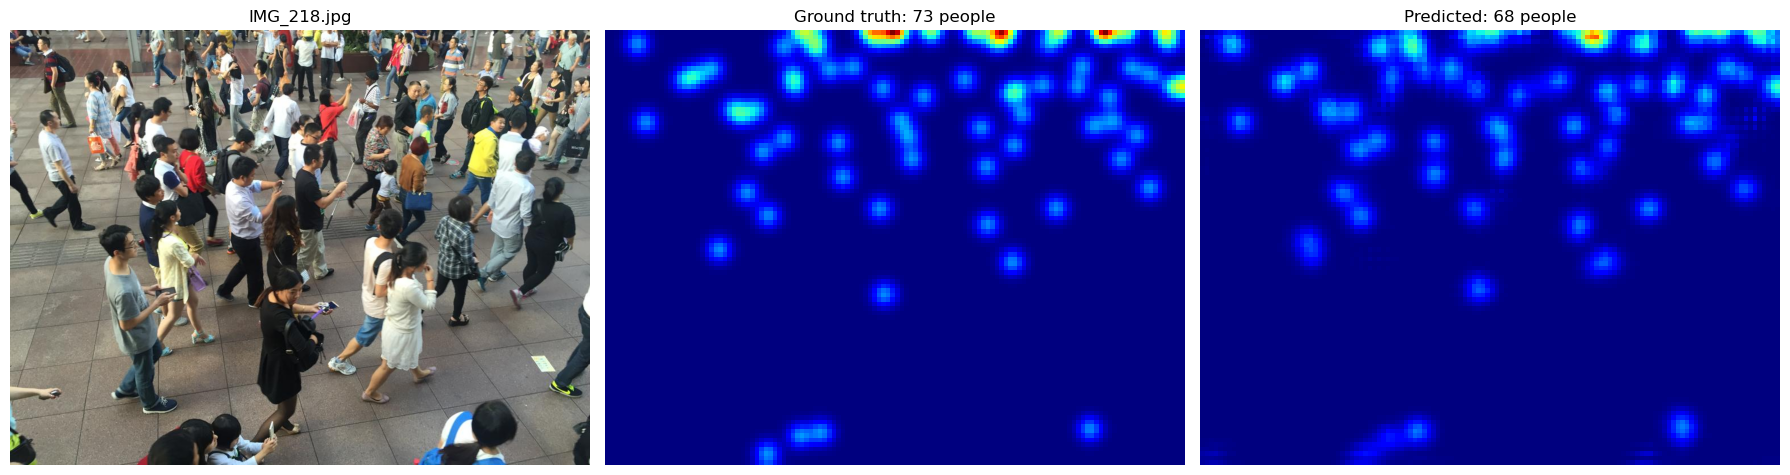

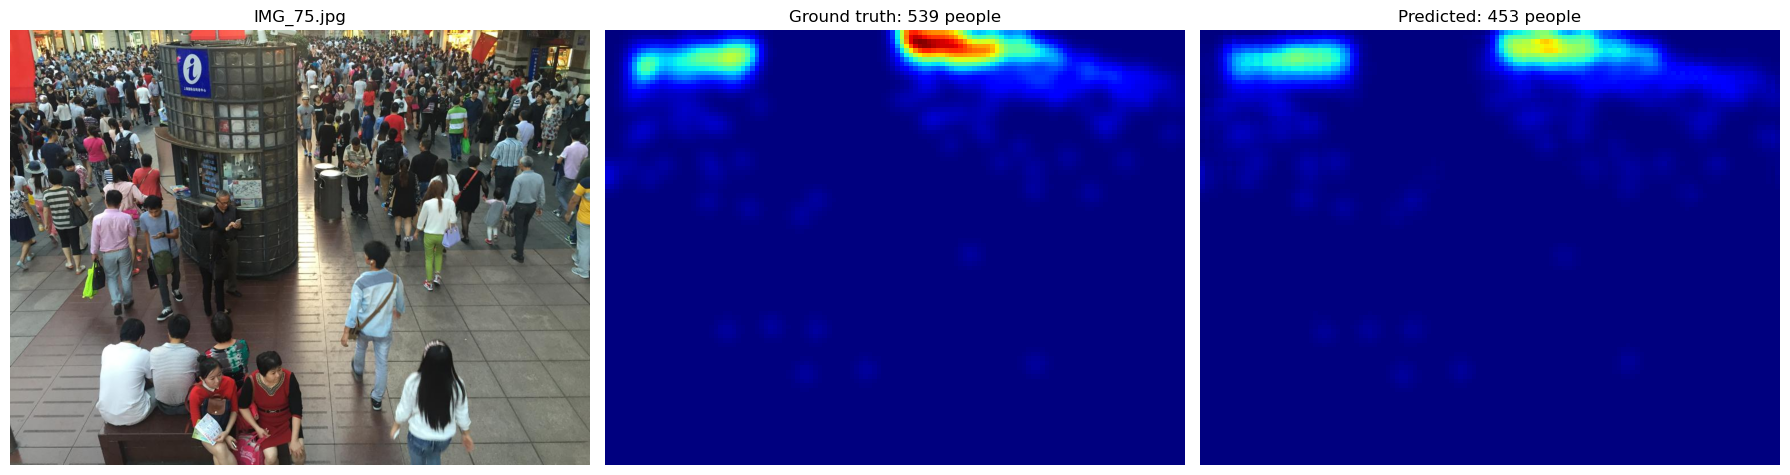

In [10]:
os.makedirs("results", exist_ok=True)

def show_prediction(name):
    idx = test_set.names.index(name)
    img, den = test_set[idx]
    with torch.no_grad():
        pred = model(img.unsqueeze(0).to(device))[0, 0].cpu().numpy()
    gt = den[0].numpy()
    photo = cv2.cvtColor(cv2.imread(f"data/part_B/test_data/images/{name}"), cv2.COLOR_BGR2RGB)

    vmax = max(gt.max(), pred.max())
    fig, ax = plt.subplots(1, 3, figsize=(18, 5))
    ax[0].imshow(photo);                                  ax[0].set_title(name)
    ax[1].imshow(gt,   cmap="jet", vmin=0, vmax=vmax);    ax[1].set_title(f"Ground truth: {gt.sum():.0f} people")
    ax[2].imshow(pred, cmap="jet", vmin=0, vmax=vmax);    ax[2].set_title(f"Predicted: {pred.sum():.0f} people")
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.savefig(f"results/{name.replace('.jpg', '')}_result.png", dpi=150, bbox_inches="tight")
    plt.show()

by_err = sorted(rows, key=lambda r: abs(r[3]))
for name in [by_err[0][0], by_err[len(by_err) // 2][0], by_err[-1][0]]:   # best, typical, worst
    show_prediction(name)